# College Football Upset Vulnerability — Notebook 11: Margin-Adjusted Elo and Parameter Sensitivity


## 0. Load saved Notebook 09/10 data and freeze the validation design


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'
INPUTS = {
    'n09_matchups': PROCESSED / 'matchup_features_offense_defense.csv',
    'n09_manifest': PROCESSED / 'offense_defense_feature_manifest.json',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'splits': PROCESSED / 'split_manifest.json',
    'n10_matchups': PROCESSED / 'matchup_features_historical_efficiency_elo.csv',
    'n10_manifest': PROCESSED / 'historical_efficiency_elo_feature_manifest.json',
    'n10_predictions': OUTPUT_DIR / 'historical_efficiency_elo_oof_predictions_2019_2023.csv',
}
missing = [f'{name}: {path}' for name,path in INPUTS.items() if not path.is_file()]
if missing:
    raise FileNotFoundError('Run Notebook 09/10 export cells first. Missing:\n' + '\n'.join(missing))
matchups = pd.read_csv(INPUTS['n09_matchups'],parse_dates=['date'],low_memory=False)
reference = pd.read_csv(INPUTS['n10_matchups'],low_memory=False)
eligibility = pd.read_csv(INPUTS['eligibility'],low_memory=False)
manifest09 = json.loads(INPUTS['n09_manifest'].read_text(encoding='utf-8'))
manifest10 = json.loads(INPUTS['n10_manifest'].read_text(encoding='utf-8'))
splits = json.loads(INPUTS['splits'].read_text(encoding='utf-8'))
prior_oof = pd.read_csv(INPUTS['n10_predictions'])
BASE88 = list(manifest09['feature_sets']['efficiency_without_scoring'])
folds = splits['validation_folds']
TEST_SEASONS = set(map(int,splits['test_seasons']))
assert TEST_SEASONS == {2024,2025}
assert [int(f['validation_season']) for f in folds] == [2019,2020,2021,2022,2023]
assert len(BASE88)==88 and len(BASE88)==len(set(BASE88))
assert set(BASE88).issubset(matchups.columns)
assert matchups.game_id.is_unique and reference.game_id.is_unique
assert len(matchups)==len(reference)==len(eligibility)==18300
assert manifest10['elo_rules']['k']==24.0
assert manifest10['elo_rules']['home_advantage_rating_points']==55.0
assert manifest10['elo_rules']['offseason_retention']==0.75
print('Loaded',len(matchups),'pregame matchups, including reserved test rows in source files.')
print('Only seasons 2004–2023 will enter the Elo and validation experiments.')
print('Notebook 09 baseline:',len(BASE88),'features | sklearn',sklearn.__version__)

Mounted at /content/drive
Loaded 18300 pregame matchups, including reserved test rows in source files.
Only seasons 2004–2023 will enter the Elo and validation experiments.
Notebook 09 baseline: 88 features | sklearn 1.6.1


## 1. Construct our chronological Elo game ledger


In [ ]:
def parse_boolean(series):
    vals=series.astype('string').str.strip().str.lower()
    assert vals.isin(['true','false','1','0']).all(), f'Unexpected boolean values: {vals.unique()}'
    return vals.isin(['true','1'])

KEY = ['game_id','season','home','away']
ledger = matchups.loc[~matchups.season.isin(TEST_SEASONS),
    ['game_id','season','date','home','away','neutral','home_win','home_margin']].merge(
    eligibility[KEY+['primary_fbs_fbs']],on=KEY,how='left',validate='one_to_one',indicator=True)
assert ledger['_merge'].eq('both').all()
ledger.drop(columns='_merge',inplace=True)
ledger['is_neutral']=parse_boolean(ledger['neutral'])
ledger['elo_update_game']=parse_boolean(ledger['primary_fbs_fbs'])
ledger=ledger.sort_values(['season','date','game_id'],kind='stable').reset_index(drop=True)
assert ledger.game_id.is_unique and ledger.home_win.isin([0,1]).all()
assert ledger.home_margin.notna().all() and (ledger.home_margin!=0).all()
assert ((ledger.home_margin>0).astype(int)==ledger.home_win.astype(int)).all()
assert ledger.date.notna().all() and ledger.season.between(2004,2023).all()
assert not pd.concat([
  ledger[['date','home']].rename(columns={'home':'team'}),
  ledger[['date','away']].rename(columns={'away':'team'})
]).duplicated(['date','team']).any()
assert len(ledger)==int((~matchups.season.isin(TEST_SEASONS)).sum())
assert int(ledger.elo_update_game.sum())==14563
print('Chronological ledger:',len(ledger),'all games through 2023')
print('FBS vs FBS rating updates:',int(ledger.elo_update_game.sum()))
print('Reserved 2024–2025 outcomes read into Elo:',0)

Chronological ledger: 16447 all games through 2023
FBS vs FBS rating updates: 14563
Reserved 2024–2025 outcomes read into Elo: 0


## 2. Predeclare a small set of Elo variations and build pregame snapshots



In [ ]:
from dataclasses import dataclass, asdict, replace

@dataclass(frozen=True)
class EloSettings:
    k: float = 24.0
    retention: float = 0.75
    scale: float = 400.0
    home_bonus: float = 55.0
    mov: str = 'none'

DEFAULT = EloSettings()
VARIANTS = {
    'traditional': DEFAULT,
    'mov_log': replace(DEFAULT,mov='log_capped'),
    'mov_winner_adjusted': replace(DEFAULT,mov='winner_adjusted'),
    'retain_50': replace(DEFAULT,retention=0.50),
    'retain_90': replace(DEFAULT,retention=0.90),
    'k_16': replace(DEFAULT,k=16.0),
    'k_32': replace(DEFAULT,k=32.0),
    'scale_350': replace(DEFAULT,scale=350.0),
    'scale_450': replace(DEFAULT,scale=450.0),
    'home_30': replace(DEFAULT,home_bonus=30.0),
    'home_80': replace(DEFAULT,home_bonus=80.0),
    'mov_log_retain50': replace(DEFAULT,mov='log_capped',retention=0.50),
    'mov_log_retain90': replace(DEFAULT,mov='log_capped',retention=0.90),
    'mov_log_k16': replace(DEFAULT,mov='log_capped',k=16.0),
    'mov_log_k32': replace(DEFAULT,mov='log_capped',k=32.0),
    'mov_winner_k16': replace(DEFAULT,mov='winner_adjusted',k=16.0),
}
assert len(VARIANTS)==16 and len(set(VARIANTS.values()))==16
assert all(c.mov in ['none','log_capped','winner_adjusted'] and
           0<=c.retention<=1 and c.scale>0 and c.k>0 for c in VARIANTS.values())

ELO_FEATURES=['elo_home_rating','elo_away_rating','elo_diff',
              'elo_expected_home','elo_home_prior_games','elo_away_prior_games']

def get_p(home_r,away_r,neutral,cfg):
    gap=home_r-away_r+(0.0 if neutral else cfg.home_bonus)
    return 1.0/(1.0+10.0**(-gap/cfg.scale))

def update_multiplier(margin, pregame_home_gap, home_won, mode):
    if mode=='none': return 1.0
    if mode=='log_capped':
        return float(np.clip(np.log1p(abs(margin))/np.log(8.0),0.5,2.5))
    if mode=='winner_adjusted':
        winner_edge=pregame_home_gap*(1.0 if home_won else -1.0)
        return float(np.clip(np.log1p(abs(margin))*2.2/max(0.7,2.2+0.001*winner_edge),0.5,3.0))
    raise ValueError(mode)

def simulate_elo(cfg):
    # Each ledger row is a chronological (pregame) snapshot. Current outcomes are
    # used ONLY below after snapshotting; same-day duplicate teams prohibited.
    ratings={}; games_seen={}; current_season=None; rows=[]
    for g in ledger.itertuples(index=False):
        year=int(g.season)
        if current_season is None: current_season=year
        if year!=current_season:
            assert year>current_season
            for yr in range(current_season+1,year+1):
                for team in ratings:
                    ratings[team]=1500.0+cfg.retention*(ratings[team]-1500.0)
            current_season=year
        rh=ratings.get(g.home,1500.0); ra=ratings.get(g.away,1500.0)
        p=get_p(rh,ra,bool(g.is_neutral),cfg)
        rows.append((g.game_id,rh,ra,rh-ra,p,
                     games_seen.get(g.home,0),games_seen.get(g.away,0)))
        if bool(g.elo_update_game):
            gap=rh-ra+(0.0 if g.is_neutral else cfg.home_bonus)
            mult=update_multiplier(g.home_margin,gap,g.home_win,cfg.mov)
            delta=cfg.k*mult*(float(g.home_win)-p)
            ratings[g.home]=rh+delta;ratings[g.away]=ra-delta
            games_seen[g.home]=games_seen.get(g.home,0)+1
            games_seen[g.away]=games_seen.get(g.away,0)+1
    out=pd.DataFrame(rows,columns=['game_id']+ELO_FEATURES)
    assert len(out)==len(ledger) and out.game_id.is_unique
    assert np.isfinite(out[ELO_FEATURES]).all().all()
    assert out.elo_expected_home.between(0,1).all()
    return out

# Per-variant pregame features, computed exactly once, from the same ledger.
# Namespaced columns prevent one experiment from silently overwriting another.
elo_by_variant={name:simulate_elo(cfg) for name,cfg in VARIANTS.items()}
print('Pregame Elo snapshots built:',len(elo_by_variant),'variants ×',len(ledger),'games')
print('Parameter configurations:')
display(pd.DataFrame([{'variant':k,**asdict(v)} for k,v in VARIANTS.items()]))

Pregame Elo snapshots built: 16 variants × 16447 games
Parameter configurations:


,variant,k,retention,scale,home_bonus,mov
0,traditional,24.0,0.75,400.0,55.0,none
1,mov_log,24.0,0.75,400.0,55.0,log_capped
2,mov_winner_adjusted,24.0,0.75,400.0,55.0,winner_adjusted
3,retain_50,24.0,0.50,400.0,55.0,none
4,retain_90,24.0,0.90,400.0,55.0,none
5,k_16,16.0,0.75,400.0,55.0,none
6,k_32,32.0,0.75,400.0,55.0,none
7,scale_350,24.0,0.75,350.0,55.0,none
8,scale_450,24.0,0.75,450.0,55.0,none
9,home_30,24.0,0.75,400.0,30.0,none


## 3. Validate exact traditional-Elo reproducibility and MOV update rules



In [ ]:
reproduction=reference.loc[reference.season.between(2004,2023),['game_id',*ELO_FEATURES]].merge(
    elo_by_variant['traditional'],on='game_id',how='outer',validate='one_to_one',indicator=True,
    suffixes=('_n10','_n11'))
assert len(reproduction)==len(ledger) and reproduction['_merge'].eq('both').all()
max_feature_diff={}
for c in ELO_FEATURES:
    error=(reproduction[f'{c}_n10']-reproduction[f'{c}_n11']).abs().max()
    max_feature_diff[c]=float(error)
    assert error < 1e-8,(c,error)
print('PASS: Traditional Elo exactly reproduces Notebook 10 within 1e-8, every game.')
display(pd.Series(max_feature_diff,name='max_absolute_difference').to_frame())

# Inspect pregame and next-game rating changes using source scores, independently
# of simulate_elo's state. Stay within same season to avoid offseason resets.
probe=ledger.loc[ledger.elo_update_game].sample(n=100,random_state=73)
for name in ['traditional','mov_log','mov_winner_adjusted']:
    cfg=VARIANTS[name]
    table=ledger.merge(elo_by_variant[name],on='game_id',validate='one_to_one')
    keyed=table.set_index('game_id')
    for g in probe.itertuples(index=False):
        snap=keyed.loc[g.game_id]
        gap=snap.elo_home_rating-snap.elo_away_rating+(0 if g.is_neutral else cfg.home_bonus)
        expected_p=1/(1+10**(-gap/cfg.scale))
        assert np.isclose(expected_p,snap.elo_expected_home,atol=1e-12)
        delta=cfg.k*update_multiplier(g.home_margin,gap,g.home_win,cfg.mov)*(g.home_win-expected_p)
        for team,wanted in ((g.home,snap.elo_home_rating+delta),(g.away,snap.elo_away_rating-delta)):
            later=table.loc[(table.season.eq(g.season)) & (table.date.gt(g.date)) &
                            (table.home.eq(team)|table.away.eq(team))].sort_values(['date','game_id'])
            if later.empty:continue
            next_game=later.iloc[0]
            observed=next_game.elo_home_rating if next_game.home==team else next_game.elo_away_rating
            assert np.isclose(observed,wanted,atol=1e-8,rtol=1e-11),(name,team,g.game_id)
print('PASS: 100 independently recomputed updates for each of three MOV types.')
print('PASS: 2024–2025 is absent from all Elo snapshots and audits.')

sample=ledger.loc[ledger.season.eq(2023),['game_id','date','home','away']].merge(
    elo_by_variant['traditional'],on='game_id',validate='one_to_one')
for name in ['mov_log','mov_winner_adjusted','retain_50','retain_90']:
    sample=sample.merge(elo_by_variant[name][['game_id','elo_expected_home']].rename(
        columns={'elo_expected_home':f'p_{name}'}),on='game_id',validate='one_to_one')
print('Illustrative 2023 pregame differences (NOT a performance ranking):')
display(sample[['date','home','away','elo_expected_home','p_mov_log','p_mov_winner_adjusted','p_retain_50','p_retain_90']].head(8).round(3))

PASS: Traditional Elo exactly reproduces Notebook 10 within 1e-8, every game.


,max_absolute_difference
elo_home_rating,2.273737e-13
elo_away_rating,2.273737e-13
elo_diff,5.684342e-14
elo_expected_home,1.110223e-16
elo_home_prior_games,0.000000e+00
elo_away_prior_games,0.000000e+00


PASS: 100 independently recomputed updates for each of three MOV types.
PASS: 2024–2025 is absent from all Elo snapshots and audits.
Illustrative 2023 pregame differences (NOT a performance ranking):


,date,home,away,elo_expected_home,p_mov_log,p_mov_winner_adjusted,p_retain_50,p_retain_90
0,2023-08-26,Notre Dame,Navy,0.689,0.742,0.783,0.594,0.792
1,2023-08-26,Jacksonville State,UTEP,0.669,0.685,0.721,0.608,0.766
2,2023-08-26,New Mexico State,Massachusetts,0.695,0.727,0.805,0.655,0.719
3,2023-08-26,San Diego State,Ohio,0.602,0.594,0.557,0.572,0.648
4,2023-08-26,USC,San Jose State,0.670,0.697,0.751,0.623,0.757
5,2023-08-26,Louisiana Tech,FIU,0.618,0.650,0.655,0.587,0.660
6,2023-08-26,Vanderbilt,Hawaii,0.581,0.584,0.656,0.595,0.595
7,2023-08-31,Arizona State,Southern Utah,0.522,0.521,0.471,0.534,0.541


## 4. Standalone Elo diagnostics on the validation years


In [ ]:
ELO_TUNE_START=2014  # Five prior seasons for the first outer fold (2014–2018)
elo_predictions=ledger.loc[ledger.elo_update_game,
    ['game_id','season','date','home','away','home_win']].copy()
for name,snaps in elo_by_variant.items():
    elo_predictions=elo_predictions.merge(
        snaps[['game_id','elo_expected_home']].rename(columns={'elo_expected_home':name}),
        on='game_id',how='left',validate='one_to_one')
assert len(elo_predictions)==14563 and elo_predictions.game_id.is_unique
assert elo_predictions.home_win.isin([0,1]).all()

def score(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and len(y)>0 and np.isfinite(p).all()
    assert ((p>=0)&(p<=1)).all()
    return {'n_games':len(y),'accuracy':accuracy_score(y,p>=0.5),
            'brier':brier_score_loss(y,p),
            'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if np.unique(y).size==2 else np.nan}

outer_elo=elo_predictions.loc[elo_predictions.season.between(2019,2023)]
standalone=pd.DataFrame([
    {'variant':name,**score(outer_elo.home_win,outer_elo[name])}
    for name in VARIANTS
]).sort_values('brier').reset_index(drop=True)
print('Elo-only 2019–2023 comparison (exploratory; lower Brier better):')
display(standalone.round(5))
elo_by_year=pd.DataFrame([
    {'validation_season':yr,'variant':name,**score(frame.home_win,frame[name])}
    for yr,frame in outer_elo.groupby('season') for name in VARIANTS
])
print('Brier changes vs traditional Elo by year:')
elo_year_table=elo_by_year.pivot(index='validation_season',columns='variant',values='brier')
display((elo_year_table.sub(elo_year_table['traditional'],axis=0)).round(5))

Elo-only 2019–2023 comparison (exploratory; lower Brier better):


,variant,n_games,accuracy,brier,log_loss,roc_auc
0,mov_winner_adjusted,3646,0.70872,0.19167,0.56422,0.76822
1,mov_log_k32,3646,0.69967,0.19449,0.57161,0.76382
2,mov_winner_k16,3646,0.69940,0.19530,0.57391,0.76349
3,mov_log_retain90,3646,0.69556,0.19587,0.57305,0.75652
4,mov_log,3646,0.69611,0.19773,0.57998,0.75969
5,retain_90,3646,0.68925,0.19981,0.58336,0.74841
6,k_32,3646,0.69583,0.20050,0.58658,0.75341
7,scale_350,3646,0.69309,0.20270,0.59171,0.75074
8,mov_log_k16,3646,0.69391,0.20323,0.59351,0.75393
9,mov_log_retain50,3646,0.69583,0.20416,0.59646,0.76400


Brier changes vs traditional Elo by year:


variant,home_30,home_80,k_16,k_32,mov_log,mov_log_k16,mov_log_k32,mov_log_retain50,mov_log_retain90,mov_winner_adjusted,mov_winner_k16,retain_50,retain_90,scale_350,scale_450,traditional
validation_season,,,,,,,,,,,,,,,,
2019,0.00193,0.00023,0.00696,-0.00435,-0.00794,-0.00164,-0.01158,0.00115,-0.01211,-0.01506,-0.01074,0.01033,-0.00660,-0.00226,0.00220,0.0
2020,-0.00009,0.00225,0.00569,-0.00346,-0.00615,-0.00110,-0.00902,-0.00043,-0.00673,-0.01122,-0.00795,0.00766,-0.00341,-0.00121,0.00134,0.0
2021,0.00061,0.00157,0.00646,-0.00411,-0.00538,0.00043,-0.00881,0.00185,-0.00665,-0.01155,-0.00787,0.00881,-0.00455,-0.00172,0.00176,0.0
2022,0.00049,0.00161,0.00415,-0.00250,-0.00604,-0.00229,-0.00803,-0.00231,-0.00585,-0.00919,-0.00739,0.00505,-0.00202,-0.00094,0.00107,0.0
2023,0.00038,0.00182,0.00658,-0.00445,-0.00719,-0.00077,-0.01131,-0.00103,-0.01026,-0.01561,-0.01069,0.00730,-0.00551,-0.00176,0.00178,0.0


## 5. Select an Elo variant using *earlier seasons only*



In [ ]:
selected_rows=[];nested_parts=[];tuning_tables=[]
for f in folds:
    year=int(f['validation_season'])
    inner=elo_predictions.loc[elo_predictions.season.between(ELO_TUNE_START,year-1)]
    outer=elo_predictions.loc[elo_predictions.season.eq(year)]
    assert inner.season.max()<year and outer.season.eq(year).all()
    assert not inner.game_id.isin(outer.game_id).any()
    trials=sorted([
        (name,float(brier_score_loss(inner.home_win,inner[name]))) for name in VARIANTS
    ],key=lambda x:(x[1],x[0]))
    winner,lowest_brier=trials[0]
    selected_rows.append({'validation_season':year,'chosen_variant':winner,
                          'inner_start_season':ELO_TUNE_START,
                          'inner_last_season':year-1,'n_inner_games':len(inner),
                          'inner_best_brier':lowest_brier,
                          'inner_traditional_brier':dict(trials)['traditional']})
    tuning_tables.extend([{'validation_season':year,'variant':v,'inner_brier':b}
                          for v,b in trials])
    nested_parts.append(outer[['game_id','season','home_win']].assign(
        selected_variant=winner,nested_elo_probability=outer[winner].to_numpy()))
selections=pd.DataFrame(selected_rows)
tuning_scores=pd.DataFrame(tuning_tables)
nested_probabilities=pd.concat(nested_parts,ignore_index=True)
assert len(nested_probabilities)==3646 and nested_probabilities.game_id.is_unique
print('Chronologically selected Elo variants (no lookahead into the scored season):')
display(selections)
print('Nested-selected Elo-only Brier:',round(brier_score_loss(nested_probabilities.home_win,
                                          nested_probabilities.nested_elo_probability),6))
print('Traditional Elo-only Brier:',round(float(standalone.loc[standalone.variant.eq('traditional'),'brier'].iloc[0]),6))

Chronologically selected Elo variants (no lookahead into the scored season):


,validation_season,chosen_variant,inner_start_season,inner_last_season,n_inner_games,inner_best_brier,inner_traditional_brier
0,2019,mov_winner_adjusted,2014,2018,3833,0.187572,0.201845
1,2020,mov_winner_adjusted,2014,2019,4607,0.186100,0.200505
2,2021,mov_winner_adjusted,2014,2020,5141,0.187095,0.201170
3,2022,mov_winner_adjusted,2014,2021,5911,0.187587,0.201333
4,2023,mov_winner_adjusted,2014,2022,6687,0.189597,0.202814


Nested-selected Elo-only Brier: 0.191674
Traditional Elo-only Brier: 0.204301


## 6. Assemble the exact 88-feature baseline and Elo additions



In [ ]:
MODEL_VARIANTS = [
    'traditional','mov_log','mov_winner_adjusted',
    'retain_50','retain_90','k_16','k_32',
    'scale_350','scale_450',
]
MODEL_CONFIGS = ['baseline_88'] + [f'elo_{name}' for name in MODEL_VARIANTS]+['elo_inner_selected']
assert len(MODEL_CONFIGS)==11
all_variants=set(MODEL_VARIANTS) | set(selections.chosen_variant)
base=matchups.loc[~matchups.season.isin(TEST_SEASONS)].merge(
    eligibility[KEY+['primary_fbs_fbs']],on=KEY,how='left',validate='one_to_one',indicator=True)
assert base['_merge'].eq('both').all()
base.drop(columns='_merge',inplace=True)
base=base.loc[parse_boolean(base.primary_fbs_fbs)].copy()
assert len(base)==14563 and base.game_id.is_unique
assert base.season.between(2004,2023).all()

# Attach each fixed candidate's 6-feature pregame snapshot in separate namespaces.
for name in all_variants:
    features=elo_by_variant[name].rename(columns={c:f'{name}__{c}' for c in ELO_FEATURES})
    base=base.merge(features,on='game_id',validate='one_to_one',how='left',indicator=True)
    assert base['_merge'].eq('both').all()
    base.drop(columns='_merge',inplace=True)
# Preserve a fixed, honest chronological choice on each outer fold.
# For training years, avoid selection based on future validation outcomes: the
# pre-2019 inner choice (trained on 2014–2018) is used in all older training
# rows, then the earlier historical variant selected for each subsequent year.
# This adds no future information to the feature, as each underlying Elo snapshot
# is pregame, and all selected parameters for a given outer fold are fixed using
# years before that fold. The inner choice is attached separately PER FOLD below.
for name in MODEL_VARIANTS:
    assert all(f'{name}__{c}' in base for c in ELO_FEATURES)
for c in BASE88:
    if c=='neutral':
        base[c]=parse_boolean(base[c]).astype(float)
    else:
        before=int(base[c].isna().sum())
        base[c]=pd.to_numeric(base[c],errors='coerce')
        assert int(base[c].isna().sum())==before,(c,'unexpected coercion')
assert base[BASE88].select_dtypes(exclude=[np.number]).empty

# Config-specific training source: use the selected Elo parameters from earlier
# years for the entire fold, avoiding mixed parameter histories in training.
# This is an inner-selected parameter, not a learned season-by-season blend.
print('Modeling rows:',len(base),'FBS-vs-FBS games; no 2024–2025 rows.')
print('Baseline: 88 features | Each Elo-augmented classifier: 94 features')
print('Models compared:',MODEL_CONFIGS)

Modeling rows: 14563 FBS-vs-FBS games; no 2024–2025 rows.
Baseline: 88 features | Each Elo-augmented classifier: 94 features
Models compared: ['baseline_88', 'elo_traditional', 'elo_mov_log', 'elo_mov_winner_adjusted', 'elo_retain_50', 'elo_retain_90', 'elo_k_16', 'elo_k_32', 'elo_scale_350', 'elo_scale_450', 'elo_inner_selected']


## 7. Evaluate the same five expanding-window Logistic Regression folds



In [ ]:
def make_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42)),
    ])

fold_rows=[];prediction_parts=[]
for f in folds:
    year=int(f['validation_season']);start,end=map(int,f['train_seasons'])
    assert start==2004 and end==year-1
    train=base.loc[base.season.between(start,end)]
    valid=base.loc[base.season.eq(year)]
    assert train.season.max()<year and len(train)>0 and len(valid)>0
    assert set(train.game_id).isdisjoint(valid.game_id)
    selected=selections.loc[selections.validation_season.eq(year),'chosen_variant'].iloc[0]
    for name in MODEL_CONFIGS:
        if name=='baseline_88':features=BASE88
        elif name=='elo_inner_selected':features=BASE88+[f'{selected}__{c}' for c in ELO_FEATURES]
        else:
            variant=name.removeprefix('elo_')
            features=BASE88+[f'{variant}__{c}' for c in ELO_FEATURES]
        model=make_pipeline()
        model.fit(train[features],train.home_win.astype(int))
        p=model.predict_proba(valid[features])[:,list(model.named_steps['classifier'].classes_).index(1)]
        fold_rows.append({'validation_season':year,'fold':f['fold'],'model':name,
                          'elo_variant':selected if name=='elo_inner_selected' else
                           (None if name=='baseline_88' else name.removeprefix('elo_')),
                          'n_train':len(train),**score(valid.home_win,p)})
        tmp=valid[['game_id','season','date','home','away','home_win','season_stage']].copy()
        tmp['model']=name;tmp['elo_variant']=selected if name=='elo_inner_selected' else (
            None if name=='baseline_88' else name.removeprefix('elo_'))
        tmp['predicted_p_home_win']=p
        prediction_parts.append(tmp)
    print(f'Validated {year}: {len(train):,} train / {len(valid):,} validation games | inner Elo choice = {selected}')
fold_scores=pd.DataFrame(fold_rows)
oof=pd.concat(prediction_parts,ignore_index=True)
assert oof.groupby('model').size().eq(3646).all()
assert oof.groupby(['model','game_id']).size().eq(1).all()
assert not oof.season.isin(TEST_SEASONS).any()

# Check reproduction against Notebook 10's traditional Elo-augmented model.
previous=prior_oof.loc[prior_oof.model.eq('elo_only'),
    ['game_id','season','home_win','predicted_p_home_win']].rename(
        columns={'predicted_p_home_win':'p10'})
current=oof.loc[oof.model.eq('elo_traditional'),
    ['game_id','season','home_win','predicted_p_home_win']].rename(
        columns={'predicted_p_home_win':'p11'})
paired=previous.merge(current,on=['game_id','season'],how='outer',validate='one_to_one',
                      indicator=True,suffixes=('_10','_11'))
assert len(paired)==3646 and paired['_merge'].eq('both').all()
assert (paired.home_win_10==paired.home_win_11).all()
diff=(paired.p10-paired.p11).abs()
reproduce_model={
    'mean_abs_probability_difference':float(diff.mean()),
    'max_abs_probability_difference':float(diff.max()),
    'changed_winner_predictions':int(((paired.p10>=0.5)!=(paired.p11>=0.5)).sum()),
    'brier10':float(brier_score_loss(paired.home_win_10,paired.p10)),
    'brier11':float(brier_score_loss(paired.home_win_11,paired.p11)),
}
reproduce_model['abs_brier_difference']=abs(reproduce_model['brier11']-reproduce_model['brier10'])
print('Notebook 10 ↔ Notebook 11 traditional Elo model reproduction:')
display(pd.Series(reproduce_model).to_frame('value'))
assert reproduce_model['abs_brier_difference']<1e-4, 'Material baseline discrepancy—investigate.'

Validated 2019: 10,917 train / 774 validation games | inner Elo choice = mov_winner_adjusted
Validated 2020: 11,691 train / 534 validation games | inner Elo choice = mov_winner_adjusted
Validated 2021: 12,225 train / 770 validation games | inner Elo choice = mov_winner_adjusted
Validated 2022: 12,995 train / 776 validation games | inner Elo choice = mov_winner_adjusted
Validated 2023: 13,771 train / 792 validation games | inner Elo choice = mov_winner_adjusted
Notebook 10 ↔ Notebook 11 traditional Elo model reproduction:


,value
mean_abs_probability_difference,1.719641e-17
max_abs_probability_difference,1.110223e-16
changed_winner_predictions,0.000000e+00
brier10,1.878772e-01
brier11,1.878772e-01
abs_brier_difference,0.000000e+00


## 8. Compare predictive value and season-stage effects



Pooled 2019–2023 model results (lower Brier is better):


,model,n_games,accuracy,brier,log_loss,roc_auc
0,elo_inner_selected,3646,0.71092,0.18659,0.55270,0.78210
1,elo_mov_winner_adjusted,3646,0.71092,0.18659,0.55270,0.78210
2,elo_retain_90,3646,0.71393,0.18709,0.55374,0.78102
3,baseline_88,3646,0.71942,0.18724,0.55539,0.78003
4,elo_k_32,3646,0.71338,0.18760,0.55506,0.77957
5,elo_mov_log,3646,0.71201,0.18775,0.55563,0.77923
6,elo_scale_350,3646,0.71558,0.18787,0.55584,0.77896
7,elo_traditional,3646,0.71558,0.18788,0.55588,0.77885
8,elo_scale_450,3646,0.71503,0.18801,0.55627,0.77853
9,elo_k_16,3646,0.71476,0.18809,0.55658,0.77835


Brier difference versus original 88-feature baseline (negative is better):


model,baseline_88,elo_inner_selected,elo_k_16,elo_k_32,elo_mov_log,elo_mov_winner_adjusted,elo_retain_50,elo_retain_90,elo_scale_350,elo_scale_450,elo_traditional
validation_season,,,,,,,,,,,
2019,0.0,-0.001644,0.000111,0.000225,-0.000291,-0.001644,0.001054,-0.000912,0.000360,0.000237,0.000193
2020,0.0,0.002436,0.003455,0.002361,0.002971,0.002436,0.003417,0.002595,0.002918,0.003331,0.002944
2021,0.0,0.000800,0.001228,0.001065,0.001691,0.000800,0.001635,0.000898,0.001216,0.001303,0.001240
2022,0.0,-0.002072,-0.000666,-0.001085,-0.001299,-0.002072,-0.000658,-0.001588,-0.000889,-0.000790,-0.000857
2023,0.0,-0.001752,0.000927,-0.000111,0.000247,-0.001752,0.000832,-0.000876,0.000266,0.000586,0.000404


Brier change from traditional-Elo model (negative is better):


model,baseline_88,elo_inner_selected,elo_k_16,elo_k_32,elo_mov_log,elo_mov_winner_adjusted,elo_retain_50,elo_retain_90,elo_scale_350,elo_scale_450,elo_traditional
validation_season,,,,,,,,,,,
2019,-0.000193,-0.001837,-0.000081,0.000032,-0.000484,-0.001837,0.000861,-0.001105,0.000168,0.000044,0.0
2020,-0.002944,-0.000508,0.000511,-0.000584,0.000027,-0.000508,0.000473,-0.000349,-0.000026,0.000387,0.0
2021,-0.001240,-0.000439,-0.000011,-0.000175,0.000451,-0.000439,0.000395,-0.000341,-0.000024,0.000064,0.0
2022,0.000857,-0.001216,0.000191,-0.000228,-0.000442,-0.001216,0.000199,-0.000731,-0.000032,0.000067,0.0
2023,-0.000404,-0.002156,0.000522,-0.000515,-0.000157,-0.002156,0.000428,-0.001281,-0.000138,0.000182,0.0


Brier score by stage for key candidates:


model,baseline_88,elo_inner_selected,elo_mov_log,elo_mov_winner_adjusted,elo_traditional
season_stage,,,,,
0 FBS games,0.17817,0.17524,0.17764,0.17524,0.17869
1–3 FBS games,0.18983,0.18668,0.18861,0.18668,0.18918
4–7 FBS games,0.18779,0.19056,0.19020,0.19056,0.18970
8+ FBS games,0.18760,0.18618,0.18791,0.18618,0.18800


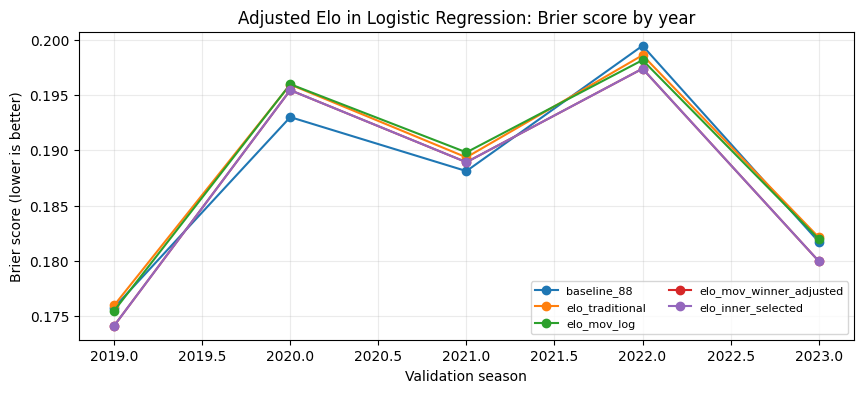

REMINDER: These are repeatedly used exploratory validation years, not final-test scores.


In [ ]:
pooled=pd.DataFrame([
    {'model':name,**score(part.home_win,part.predicted_p_home_win)}
    for name,part in oof.groupby('model')
]).sort_values('brier').reset_index(drop=True)
print('Pooled 2019–2023 model results (lower Brier is better):')
display(pooled.round(5))
per_year=fold_scores.pivot(index='validation_season',columns='model',values='brier')
delta=per_year.sub(per_year['baseline_88'],axis=0)
print('Brier difference versus original 88-feature baseline (negative is better):')
display(delta.round(6))
print('Brier change from traditional-Elo model (negative is better):')
display((per_year.sub(per_year['elo_traditional'],axis=0)).round(6))

stage_rows=[]
for (name,stage),frame in oof.groupby(['model','season_stage'],observed=False):
    if frame.empty:continue
    stage_rows.append({'model':name,'season_stage':stage,**score(frame.home_win,frame.predicted_p_home_win)})
by_stage=pd.DataFrame(stage_rows)
stages=['0 FBS games','1–3 FBS games','4–7 FBS games','8+ FBS games']
leading=['baseline_88','elo_traditional','elo_mov_log','elo_mov_winner_adjusted','elo_inner_selected']
print('Brier score by stage for key candidates:')
display(by_stage.loc[by_stage.model.isin(leading)].pivot(
    index='season_stage',columns='model',values='brier').reindex(stages).round(5))

fig,ax=plt.subplots(figsize=(10,4))
for name in leading:
    ax.plot(per_year.index,per_year[name],marker='o',label=name)
ax.set_xlabel('Validation season');ax.set_ylabel('Brier score (lower is better)')
ax.set_title('Adjusted Elo in Logistic Regression: Brier score by year')
ax.grid(alpha=.25);ax.legend(fontsize=8,ncol=2)
plt.show()
print('REMINDER: These are repeatedly used exploratory validation years, not final-test scores.')

## 9. Export experiment artifacts and freeze hypotheses


In [ ]:
PROCESSED.mkdir(parents=True,exist_ok=True)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PATHS={
    'elo_snapshot_features':PROCESSED/'elo_parameter_variants_pregame_2004_2023.csv',
    'manifest':PROCESSED/'elo_parameter_sensitivity_manifest.json',
    'elo_standalone_scores':OUTPUT_DIR/'elo_parameter_standalone_scores.csv',
    'elo_standalone_by_year':OUTPUT_DIR/'elo_parameter_standalone_by_year.csv',
    'inner_tuning_scores':OUTPUT_DIR/'elo_parameter_inner_tuning_scores.csv',
    'inner_selected_variants':OUTPUT_DIR/'elo_parameter_inner_selected_variants.csv',
    'model_fold_scores':OUTPUT_DIR/'elo_parameter_model_fold_scores.csv',
    'model_pooled_scores':OUTPUT_DIR/'elo_parameter_model_pooled_scores.csv',
    'model_oof_predictions':OUTPUT_DIR/'elo_parameter_model_oof_predictions_2019_2023.csv',
    'model_scores_by_stage':OUTPUT_DIR/'elo_parameter_model_scores_by_stage.csv',
    'model_brier_differences_by_year':OUTPUT_DIR/'elo_parameter_model_brier_deltas_by_year.csv',
}
# Exactly the pregame Elo snapshots and keys (through 2023) needed for reproduction.
wide=ledger[['game_id','season','date','home','away']].copy()
for name,snap in elo_by_variant.items():
    fields=snap[['game_id','elo_home_rating','elo_away_rating','elo_expected_home']].rename(
        columns={c:f'{name}__{c}' for c in ['elo_home_rating','elo_away_rating','elo_expected_home']})
    wide=wide.merge(fields,on='game_id',validate='one_to_one',how='left')
assert len(wide)==len(ledger) and wide.game_id.is_unique
wide.to_csv(PATHS['elo_snapshot_features'],index=False)
standalone.to_csv(PATHS['elo_standalone_scores'],index=False)
elo_by_year.to_csv(PATHS['elo_standalone_by_year'],index=False)
tuning_scores.to_csv(PATHS['inner_tuning_scores'],index=False)
selections.to_csv(PATHS['inner_selected_variants'],index=False)
fold_scores.to_csv(PATHS['model_fold_scores'],index=False)
pooled.to_csv(PATHS['model_pooled_scores'],index=False)
oof.to_csv(PATHS['model_oof_predictions'],index=False)
by_stage.to_csv(PATHS['model_scores_by_stage'],index=False)
delta.to_csv(PATHS['model_brier_differences_by_year'])
configuration={
    'experiment':'Notebook 11: Margin-adjusted Elo and parameter sensitivity',
    'baseline':'Notebook 09 efficiency_without_scoring (88 features)',
    'elo_reference':'Notebook 10 traditional (K=24, retention=.75, scale=400, HFA=55)',
    'elo_settings':{k:asdict(v) for k,v in VARIANTS.items()},
    'model_variants':MODEL_CONFIGS,
    'elo_features':ELO_FEATURES,
    'mov_log_capped':'clip(log1p(abs(score_margin))/log(8),0.5,2.5)',
    'mov_winner_adjusted':'clip(log1p(abs(score_margin))*2.2/max(0.7,2.2+winner_pregame_edge*0.001),0.5,3.0)',
    'only_elo_updates_for':'verified FBS-vs-FBS games',
    'modeling_data_seasons':[2004,2023],
    'validation_seasons':[2019,2020,2021,2022,2023],
    'inner_elo_selection':'lowest Elo-alone Brier on FBS-FBS games 2014 through prior season; apply selection to full model fit within each fold',
    'selected_variants_by_year':selected_rows,
    'folds':folds,
    'primary_model_metric':'pooled outer validation Brier score',
    'test_seasons_untouched':sorted(TEST_SEASONS),
    'traditional_elo_feature_max_abs_error':max_feature_diff,
    'model_reproduction':reproduce_model,
    'software':{'pandas':pd.__version__,'scikit_learn':sklearn.__version__},
    'warnings':['2019–2023 repeatedly used for exploratory model selection in earlier notebooks',
                'inner Elo criterion optimizes standalone Elo Brier, not incremental ML-model Brier',
                '2024–2025 holdout outcomes were not read into Elo calculation, scored or used to select configurations']
}
PATHS['manifest'].write_text(json.dumps(configuration,indent=2,default=str),encoding='utf-8')
print('Saved',len(PATHS),'artifacts:')
for name,path in PATHS.items():print(f' {name}: {path}')
print('The 2024–2025 reserved holdout remains untouched. Next: returning production.')

Saved 11 artifacts:
 elo_snapshot_features: /content/drive/MyDrive/CFB_Upset_Project/data/processed/elo_parameter_variants_pregame_2004_2023.csv
 manifest: /content/drive/MyDrive/CFB_Upset_Project/data/processed/elo_parameter_sensitivity_manifest.json
 elo_standalone_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_standalone_scores.csv
 elo_standalone_by_year: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_standalone_by_year.csv
 inner_tuning_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_inner_tuning_scores.csv
 inner_selected_variants: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_inner_selected_variants.csv
 model_fold_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_model_fold_scores.csv
 model_pooled_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/elo_parameter_model_pooled_scores.csv
 model_oof_predictions